# Developer Salary Analysis — Stack Overflow 2025

**Question.** How does professional experience relate to developer salary, and how much of the difference between markets is explained by country?

**Data.** Stack Overflow Developer Survey 2025: 49,191 responses, 172 columns. Salaries are taken from `ConvertedCompYearly`, which the survey publisher has already converted to annual USD - currency parsing is therefore out of scope.

**Structure.**
- *Data quality* - survey wording, response rates, sample composition.
- *Preparation of cleaned data* - population definition, filtering rules, loss table.
- *Chapter A* - inference statistics built from their definitions, on the whole sample.
- *Chapter B* - multiple regression on salaried professional developers in the United States, Germany and India.

Standard library functions are used to verify results that are first computed from their formulas, not to replace them: the aim is to understand each method rather than to call it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt  
from scipy import stats
import statsmodels.api as sm
import seaborn as sns

## Loading the data

The survey ships as two files: the responses and the schema, which holds the exact wording of every question.

In [2]:
pd.set_option('display.float_format', '{:.2f}'.format)

In [3]:
# 49,191 rows x 172 cols; low_memory=False reads each column in one pass, so mixed-type survey text fields are typed once 
# instead of chunk by chunk
stack_data = pd.read_csv("..\\data\\results.txt", encoding="utf-8", low_memory=False)
stack_schema = pd.read_csv("..\\data\\schema.txt", encoding="utf-8", low_memory=False)
stack_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Columns: 172 entries, ResponseId to JobSat
dtypes: float64(52), int64(1), str(119)
memory usage: 64.6 MB


In [4]:
stack_data.columns[stack_data.columns.str.contains('comp', case=False, na=False)]

Index(['CompTotal', 'AIComplex', 'ConvertedCompYearly'], dtype='str')

### First look at the salary column

count 23,947 - fewer than half of the 49,191 respondents reported a salary. mean 101,762 against a median of 75,320: the distribution is strongly right-skewed. min 1 and max 50,000,000 are not plausible salaries, so the column needs a validity filter before any statistic is computed on it.

Three facts to carry forward: heavy non-response, right skew and invalid values at both ends.

In [5]:
salary = stack_data['ConvertedCompYearly']
salary.describe()

count      23947.00
mean      101761.54
std       461756.90
min            1.00
25%        38171.00
50%        75320.00
75%       120596.00
max     50000000.00
Name: ConvertedCompYearly, dtype: float64

# Data quality: diagnostics

## Survey schema

Column names alone are not sufficient: filtering on a column whose meaning was guessed from its name is a common way to produce a clean but wrong result. The three questions below define filters applied in this notebook.

In [6]:
pd.set_option("display.max_rows", 15)
stack_schema

,qid,qname,question,type,sub,sq_id
0,QID18,TechEndorse_1,What attracts you to a technology or causes yo...,RO,AI integration or AI Agent capabilities,1.00
1,QID18,TechEndorse_2,What attracts you to a technology or causes yo...,RO,Easy-to-use API,2.00
2,QID18,TechEndorse_3,What attracts you to a technology or causes yo...,RO,Robust and complete API,3.00
3,QID18,TechEndorse_4,What attracts you to a technology or causes yo...,RO,Customizable and manageable codebase,4.00
4,QID18,TechEndorse_5,What attracts you to a technology or causes yo...,RO,Reputation for quality,5.00
...,...,...,...,...,...,...
134,QID103,AIAgentObsWrite,Was the tool or tools for AI agent observabili...,TE,NaN,NaN
135,QID92,AIAgentExternal,You indicated you use or develop AI agents as ...,MC,NaN,NaN
136,QID104,AIAgentExtWrite,"Was the out-of-the-box agents, copilots or ass...",TE,NaN,NaN
137,QID100,AIHuman,"In the future, if AI can do most coding tasks,...",MC,NaN,NaN


**Employment** - the employment-status question. Used to restrict the population to salaried respondents.

In [7]:
stack_schema['question'][52]

'Which of the following best describes your current employment status?<br>'

**MainBranch** - the professional-role question. Used to restrict the population to professional developers.

In [8]:
stack_schema['question'][49]

'Are you someone who writes code? Please select one of the following options that best describes you today.'

**CompTotal** - the income question. Note the wording: total annual compensation including salary, bonuses and perks, before taxes. The question is phrased for salaried employment and it was optional - respondents could leave it empty. This explains the low response count seen above.

In [9]:
stack_schema['question'][74]

'What is your current total <b>annual</b> compensation (salary, bonuses, and perks, before taxes and deductions) in terms of your day-to-day currency?  Please enter a whole number in the box below, without any punctuation.  If you are paid hourly, please estimate an equivalent yearly salary. If you prefer not to answer, please leave the box empty. '

## Country-level diagnostics

Diagnostics for the three countries used in the multiple regression: the United States, Germany and India. Germany is the market this analysis targets; the US and India are the two largest markets in the survey and differ from it in both salary level and structure.

### Reported salaries by country

For each country: the total number of respondents, how many reported a salary, and how many fall within the [1,000; 6,000,000] range.

The salary question was left empty by 27% of respondents in the US, 29% in Germany and 57% in India. The threshold itself removes only 1-4% of the reported salaries.

Conclusion: the data loss is driven by non-response, not by the filter. Adjusting the threshold cannot recover it.

In [10]:
for country in ['United States of America', 'Germany', 'India']:
    sub = stack_data[stack_data['Country'] == country]
    print(country)
    print('   Total:                     ', len(sub))
    print('   The salary is specified:   ', sub['ConvertedCompYearly'].notna().sum())
    print('   In the range:              ', sub['ConvertedCompYearly'].between(1_000, 6_000_000).sum())

United States of America
   Total:                      7233
   The salary is specified:    5243
   In the range:               5171
Germany
   Total:                      3025
   The salary is specified:    2141
   In the range:               2118
India
   Total:                      2547
   The salary is specified:    1096
   In the range:               1053


### Main Branch by country

Sample composition by professional role. Professional developers account for 72-77% of respondents in all three countries. The composition is consistent, so this filter does not skew one country against another. The regression is built on this group only.

In [11]:
stack_data[stack_data['Country'].isin(['United States of America', 'Germany', 'India'])]\
                                .groupby('Country')['MainBranch'].value_counts(normalize=True)

Country                   MainBranch                                                                                
Germany                   I am a developer by profession                                                               0.77
                          I am not primarily a developer, but I write code sometimes as part of my work/studies        0.13
                          I code primarily as a hobby                                                                  0.04
                          I used to be a developer by profession, but no longer am                                     0.03
                          I am learning to code                                                                        0.02
                                                                                                                       ... 
United States of America  I am not primarily a developer, but I write code sometimes as part of my work/studies        0.11
               

### Employment type by country

Sample composition by employment status. Employees account for 67% of Indian respondents versus 75-76% in Germany and the US. The gap is driven by students: 18% in India against 6% in the US.

In [12]:
stack_data[stack_data['Country'].isin(['United States of America', 'Germany', 'India'])]\
                                .groupby('Country')['Employment'].value_counts(normalize=True)

Country                   Employment                                          
Germany                   Employed                                               0.76
                          Student                                                0.11
                          Independent contractor, freelancer, or self-employed   0.09
                          Not employed                                           0.03
                          Retired                                                0.01
                                                                                 ... 
United States of America  Independent contractor, freelancer, or self-employed   0.10
                          Not employed                                           0.06
                          Student                                                0.06
                          Retired                                                0.03
                          I prefer not to say                

### Employed vs freelancers by country

Descriptive statistics were computed separately for employees and for independent contractors, freelancers and self-employed respondents.

Relative dispersion is measured as the P75/P25 ratio rather than the standard deviation: salary levels differ by a factor of eight across these countries, so absolute spread is not comparable.

| Country | Employed | Freelancers |
|---------|----------|-------------|
| US      | 1.74     | 2.74        |
| Germany | 1.63     | 2.17        |
| India   | 5.00     | 7.45        |

Freelancer income is more dispersed in all three countries without exception.

**Decision: freelancers and self-employed respondents are excluded. The model covers salaried professional developers.**

- The income question is phrased in terms of salaried employment ("salary, bonuses and perks"); for a freelancer the quantity measured is undefined - it may be revenue, revenue net of costs or income after tax.
- Relative dispersion is consistently wider, which indicates a different underlying quantity rather than the same one with more noise.
- The freelance effect is not consistent across countries: negative in the US, positive in Germany, neutral in India. Capturing it correctly would require a country x employment interaction term, which is out of scope here.

The exclusion is a limitation, not a neutral choice: the model says nothing about freelance income. A separate analysis of that group would need its own treatment of the income measure.

In [13]:
for country in ['United States of America', 'India', 'Germany']:
    sub = stack_data[(stack_data['Country'] == country) & (stack_data['MainBranch'] == 'I am a developer by profession')]
    print(country)
    print('Employed info:')
    print(sub[sub['Employment'] == 'Employed']['ConvertedCompYearly'].describe())
    print('Quantile ratio:', sub[sub['Employment'] == 'Employed']['ConvertedCompYearly'].quantile(0.75) /
          sub[sub['Employment'] == 'Employed']['ConvertedCompYearly'].quantile(0.25))
    print()
    print('Independent contractor, freelancer, or self-employed info:')
    print(sub[sub['Employment'] == 'Independent contractor, freelancer, or self-employed']['ConvertedCompYearly'].describe())
    print('Quantile ratio:', sub[sub['Employment'] == 'Independent contractor, freelancer, or self-employed']['ConvertedCompYearly']
          .quantile(0.75) / sub[sub['Employment'] == 'Independent contractor, freelancer, or self-employed']['ConvertedCompYearly']
          .quantile(0.25))
    print()

United States of America
Employed info:
count      3897.00
mean     180297.84
std      189140.51
min          42.00
25%      115000.00
50%      154765.00
75%      200000.00
max     9000000.00
Name: ConvertedCompYearly, dtype: float64
Quantile ratio: 1.7391304347826086

Independent contractor, freelancer, or self-employed info:
count       320.00
mean     151171.33
std      134875.81
min          10.00
25%       70000.00
50%      129000.00
75%      192000.00
max     1300000.00
Name: ConvertedCompYearly, dtype: float64
Quantile ratio: 2.742857142857143

India
Employed info:
count       823.00
mean      48249.79
std      349020.23
min           1.00
25%        8137.00
50%       19180.00
75%       40684.00
max     9531653.00
Name: ConvertedCompYearly, dtype: float64
Quantile ratio: 4.999877104583999

Independent contractor, freelancer, or self-employed info:
count        78.00
mean      46701.60
std      126176.62
min         581.00
25%        5580.00
50%       20342.00
75%       41555.50


# Preparation of cleaned data

### Whole-sample salary filter

Manual threshold `[1,000; 6,000,000]`. The lower bound removes data-entry artefacts - the raw minimum is 1 USD per year - while staying below any realistic market: the 25th percentile of Indian salaries is about 8,100 USD, so a higher bound would cut real observations. The upper bound removes the implausible tail (raw maximum: 50,000,000 USD).

Result: 23,213 salaries. `salary_clean` is the basis for whole-sample statistics in Chapter A.

In [14]:
# Manual threshold — handles each asymmetric tail deliberately.
salary_mask = stack_data['ConvertedCompYearly'].between(1_000, 6_000_000)
salary_clean = stack_data.loc[salary_mask, 'ConvertedCompYearly']
len(salary_clean)

23213

## Filtered data by country

Each filtering rule is defined as a separate boolean mask over the full index of `stack_data`. Keeping the rules separate makes them readable one by one, lets the loss table below be computed from the same objects, and avoids the chained-indexing pitfalls of successive sub-frames.

In [15]:
country_mask = stack_data['Country'].isin(['United States of America', 'Germany', 'India'])
population_mask = (stack_data['MainBranch'] == 'I am a developer by profession') & (stack_data['Employment'] == 'Employed')
converted_salary_mask = stack_data['ConvertedCompYearly'].between(1_000, 6_000_000)
work_exp_mask = (stack_data['WorkExp'].notna()) & (stack_data['WorkExp'] <= 68)

**Population: salaried professional developers in the United States, Germany and India (Stack Overflow Survey 2025).**

The rules, applied cumulatively:

- **Step 0 - country.** The three markets described above. 12,805 respondents.
- **Step 1 - population.** `MainBranch` = developer by profession and `Employment` = Employed. Students, freelancers and the non-employed report income that is either absent or measured differently; see the diagnostics above. 7,987 respondents remain.
- **Step 2 - valid salary.** Salary reported and within `[1,000; 6,000,000]`. 6,197 remain. India loses the largest share here; analysed in the next table.
- **Step 3 - valid experience.** `WorkExp` reported and at most 68 years, the upper bound of a plausible working life. This step removes 53 respondents in total.

Final sample: **6,144 respondents**.

In [16]:
steps = [('1. population', population_mask), ('2. valid salary', converted_salary_mask), ('3. valid experience', work_exp_mask)]
remaining_by_step_data = {'0. country': stack_data.loc[country_mask, 'Country'].value_counts()}
acc = country_mask
for step_name, step_mask in steps:
    acc = acc & step_mask
    remaining_by_step_data[step_name] = stack_data.loc[acc, 'Country'].value_counts()
remaining_by_step = pd.DataFrame(remaining_by_step_data)
remaining_by_step.loc['Total'] = remaining_by_step.sum()
remaining_by_step

,0. country,1. population,2. valid salary,3. valid experience
Country,,,,
United States of America,7233,4558,3862,3839
Germany,3025,1917,1530,1521
India,2547,1512,805,784
Total,12805,7987,6197,6144


The table shows how many respondents survive each step. Steps 1 and 3 affect the three countries almost equally; step 2 does not.

After the salary filter only 53% of the Indian sample remains, against 84% in the US and 79% in Germany. The cause is non-response, not the threshold: within the filtered Indian population, 689 respondents did not report a salary at all, while only 18 were removed by the `[1,000; 6,000,000]` range.

This has a consequence for the results. Response rates are not uniform across experience levels - junior developers answer the income question less often - so the Indian sample is biased towards more experienced respondents, and the estimated Indian salary level is likely to be too high. Non-response cannot be corrected by filtering; it is recorded here as a limitation.

In [17]:
retention_pct = remaining_by_step / remaining_by_step.shift(axis=1) * 100
retention_pct = retention_pct.iloc[:,1:].astype(int)
retention_pct

,1. population,2. valid salary,3. valid experience
Country,,,
United States of America,63,84,99
Germany,63,79,99
India,59,53,97
Total,62,77,99


In [18]:
stack_data[(stack_data['Country'] == 'India') & population_mask]['ConvertedCompYearly'].isna().sum()

np.int64(689)

`df_clean` - the final sample for Chapter B, produced by combining all four masks in a single `.loc` call.

In [19]:
df_clean = stack_data.loc[country_mask & population_mask & converted_salary_mask & work_exp_mask].copy()
df_clean.info()

<class 'pandas.DataFrame'>
Index: 6144 entries, 22 to 49045
Columns: 172 entries, ResponseId to JobSat
dtypes: float64(52), int64(1), str(119)
memory usage: 8.1 MB


# Chapter A - whole-sample inference statistics

All figures in this chapter are computed on the full survey sample: all countries, all employment types, salary within `[1,000; 6,000,000]`, n = 23,213. 

The purpose of this chapter is to build the standard inference tools from their definitions rather than to describe a specific labour market. Chapter B uses the narrower population defined above.

## Standard error

The standard error measures how precisely the sample mean estimates the population mean. It is the standard deviation divided by the square root of the sample size, so it falls with n - but only with its square root: quadrupling the sample halves the error.

Computed from the definition rather than with a library function.

In [20]:
salary_std = salary_clean.std()
salary_se = salary_std / np.sqrt(len(salary_clean))
salary_se

np.float64(836.7797155474666)

## Confidence interval

The 95% interval spans roughly two standard errors either side of the sample mean (1.96 for a normal distribution).

Result: approximately 95,900 to 99,200 USD. The interval is narrow because the sample is large, but it describes the *arithmetic mean* of a heavily right-skewed distribution - a quantity that is precisely estimated and, on its own, not very informative about a typical developer. The median is 77,383 USD, about 20,000 lower.

Interpretation note: the interval describes the precision of the estimate, not the spread of salaries.

In [21]:
salary_mean = salary_clean.mean()
lower_conf_int = salary_mean - salary_se * 1.96
upper_conf_int = salary_mean + salary_se * 1.96
print('Confidence interval: ', lower_conf_int, ':', upper_conf_int)

Confidence interval:  95874.46222493747 : 99154.63870988354


## Remote Work Data

The five categories of `RemoteWork` are grouped into two: predominantly in-person and predominantly remote or flexible. Hybrid answers are assigned by which side they lean to.

In [22]:
stack_data.columns[stack_data.columns.str.contains('Remote', case=False)]

Index(['RemoteWork'], dtype='str')

In [23]:
remote_work = stack_data['RemoteWork']
remote_work.value_counts()

RemoteWork
Remote                                                                          10931
Hybrid (some remote, leans heavy to in-person)                                   6732
In-person                                                                        6042
Hybrid (some in-person, leans heavy to flexibility)                              5831
Your choice (very flexible, you can come in when you want or just as needed)     4244
Name: count, dtype: int64

### In-Person Data

In [24]:
data_in_person = stack_data[stack_data['RemoteWork'].isin(['In-person', 'Hybrid (some remote, leans heavy to in-person)']) 
                              & salary_mask]
data_in_person['RemoteWork'].value_counts()

RemoteWork
Hybrid (some remote, leans heavy to in-person)    4116
In-person                                         3081
Name: count, dtype: int64

### Remote Data

In [25]:
data_remote = stack_data[stack_data['RemoteWork'].isin(['Remote', 'Hybrid (some in-person, leans heavy to flexibility)', 
                                                          'Your choice (very flexible, you can come in when you want or just as needed)'])
                                                          & salary_mask]
data_remote['RemoteWork'].value_counts()


RemoteWork
Remote                                                                          6921
Hybrid (some in-person, leans heavy to flexibility)                             3755
Your choice (very flexible, you can come in when you want or just as needed)    2689
Name: count, dtype: int64

### In-Person Salary

In [26]:
salary_in_person = data_in_person['ConvertedCompYearly']
salary_in_person.mean()

np.float64(85111.44449076004)

### Remote Salary

In [27]:
salary_remote = data_remote['ConvertedCompYearly']
salary_remote.mean()

np.float64(103725.9188178077)

## Welch's t-test

Mean salary is 103,726 USD for the remote group and 85,111 for the in-person group - a gap of about 18,600. The t-test asks whether a gap this large could plausibly arise from sampling noise alone.

Welch's version is used because the two groups differ in both size and variance; it does not assume equal variances. The statistic is computed from its definition and checked against `scipy.stats.ttest_ind` below.

In [28]:
t_test = (salary_remote.mean() - salary_in_person.mean()) / (np.sqrt(salary_remote.var() / len(salary_remote) 
                                                                     + salary_in_person.var() / len(salary_in_person)))
t_test

np.float64(11.219800803567407)

## P-value

t ~ 11.2, p ~ 4e-29. A difference this large would essentially never occur if the two populations had the same mean, so the difference is statistically significant. The manual computation, including the Welch-Satterthwaite degrees of freedom, matches `scipy` exactly.

Significance is not the same as explanation. Remote work is distributed unevenly across countries and is more common in high-paying markets, so this gap partly measures country rather than working mode - a confounded comparison. Separating the two requires holding country constant, which is what the multiple regression in Chapter B does.

In [29]:
s1, n1 = salary_remote.var(), len(salary_remote)
s2, n2 = salary_in_person.var(), len(salary_in_person)

numerator = (s1 / n1 + s2 / n2) ** 2
denominator = (s1 / n1) ** 2 / (n1 - 1) + (s2 / n2) ** 2 / (n2 - 1)
dof = numerator / denominator
p_value = stats.t.sf(abs(t_test), dof) * 2
p_value

np.float64(4.2732315132837573e-29)

In [30]:
result = stats.ttest_ind(salary_remote, salary_in_person, equal_var=False)
result.pvalue

np.float64(4.2732315132837573e-29)

## Experience and salary

`WorkExp` is the number of years of professional coding experience. Values above 68 are treated as implausible and removed. Combined with the salary filter this leaves 22,799 respondents with both variables present.

In [31]:
stack_data['WorkExp'].value_counts().sort_index(ascending=False).head(20)

WorkExp
100.00    34
99.00      5
88.00      1
82.00      1
75.00      1
          ..
57.00      4
56.00      6
55.00     19
54.00     13
53.00      7
Name: count, Length: 20, dtype: int64

In [32]:
exp_data = stack_data[(stack_data['WorkExp'].notna()) & (stack_data['WorkExp'] <= 68) & salary_mask]
exp_salary = exp_data[['WorkExp', 'ConvertedCompYearly']]
exp_salary.info()

<class 'pandas.DataFrame'>
Index: 22799 entries, 0 to 49122
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   WorkExp              22799 non-null  float64
 1   ConvertedCompYearly  22799 non-null  float64
dtypes: float64(2)
memory usage: 534.4 KB


## Correlation

Pearson's r is first computed from its definition - the mean product of the two standardised variables - and then verified with `scipy`.

Pearson r = 0.196, Spearman ρ = 0.440.

The gap between the two is informative. Pearson measures *linear* association and is sensitive to extreme values; Spearman works on ranks and measures any *monotonic* association. A Spearman coefficient more than twice the Pearson one indicates that salary rises consistently with experience, but not in a straight line - and that the right tail of the salary distribution is distorting the linear measure. This is the first signal that the relationship should be modelled on a log scale.

In [33]:
exp = (exp_salary['WorkExp'] - exp_salary['WorkExp'].mean()) / exp_salary['WorkExp'].std()
sal = (exp_salary['ConvertedCompYearly'] - exp_salary['ConvertedCompYearly'].mean()) / exp_salary['ConvertedCompYearly'].std()

corr = (exp * sal).mean()
corr

np.float64(0.1959669659419323)

In [34]:
corr_pearson = stats.pearsonr(exp_salary['WorkExp'], exp_salary['ConvertedCompYearly'])
corr_pearson

PearsonRResult(statistic=np.float64(0.1959755617383154), pvalue=np.float64(3.6270707008264653e-196))

In [35]:
corr_spearman = stats.spearmanr(exp_salary['WorkExp'], exp_salary['ConvertedCompYearly'])
corr_spearman

SignificanceResult(statistic=np.float64(0.43980621006857), pvalue=np.float64(0.0))

A scatter plot of 22,799 points would be an unreadable blob, so density is shown with hexagonal binning: colour encodes how many respondents fall into each cell. Both the count scale and the salary axis are logarithmic, the latter because the distribution spans four orders of magnitude.

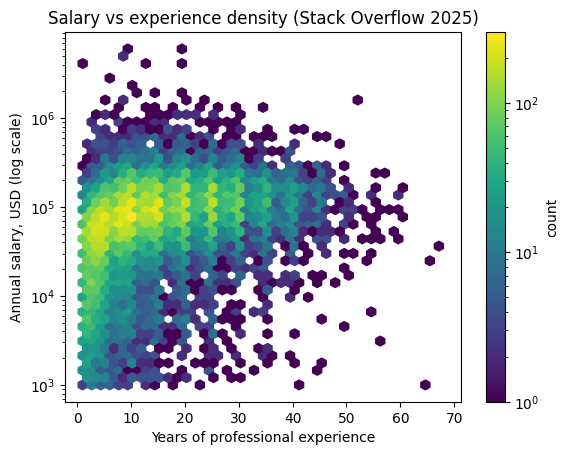

In [36]:
plt.hexbin(x=exp_salary['WorkExp'], y=exp_salary['ConvertedCompYearly'], yscale='log', bins='log', gridsize=40)
plt.colorbar(label='count')
plt.xlabel('Years of professional experience')
plt.ylabel('Annual salary, USD (log scale)')
plt.title('Salary vs experience density (Stack Overflow 2025)')
plt.show()

## Linear regression

The slope is computed from the definition - correlation scaled by the ratio of the two standard deviations - and the intercept from the requirement that the line passes through the point of means. Both are verified against `scipy.stats.linregress`.

Result: 64,039 + 2,521 x years. Read literally: each additional year of experience is worth 2,521 USD, the same amount for a junior and for a principal engineer.

Two problems with this model. It assumes a constant absolute increment, which is not how pay actually moves; and ordinary least squares fits the conditional *mean*, which in a right-skewed distribution is pulled upwards by a small number of very high earners. The fitted line accordingly sits above the bulk of the data at low experience.

In [37]:
b = corr * (exp_salary['ConvertedCompYearly'].std() / exp_salary['WorkExp'].std())
b

np.float64(2521.270521813682)

In [38]:
a = exp_salary['ConvertedCompYearly'].mean() - b * exp_salary['WorkExp'].mean()
a

np.float64(64038.62019344114)

In [39]:
regress_result = stats.linregress(exp_salary['WorkExp'], exp_salary['ConvertedCompYearly'])
regress_result.slope

np.float64(2521.3811135551423)

In [40]:
regress_result.intercept

np.float64(64037.09845709355)

The model line is drawn on an evenly spaced grid over the range of experience, not on the raw data: plotting against unsorted observations draws thousands of overlapping segments instead of one curve.

The vertical axis is logarithmic, so a straight line in dollars appears curved here.

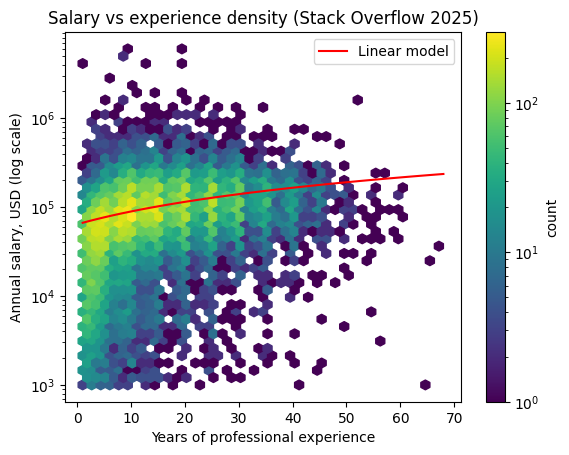

In [41]:
x_grid = np.linspace(exp_salary['WorkExp'].min(), exp_salary['WorkExp'].max(), 100)
y_linear = a + b * x_grid

plt.hexbin(x=exp_salary['WorkExp'], y=exp_salary['ConvertedCompYearly'], yscale='log', bins='log',gridsize=40)
plt.colorbar(label='count')
plt.plot(x_grid, y_linear, color='red', label='Linear model')
plt.xlabel('Years of professional experience')
plt.ylabel('Annual salary, USD (log scale)')
plt.title('Salary vs experience density (Stack Overflow 2025)')
plt.legend()
plt.show()

## Log-linear regression

The same regression is now run on the natural logarithm of salary. The model is log(salary) = a + b x years, which in dollars means salary is multiplied by a constant factor each year rather than increased by a constant amount.

Because the fit is performed on logarithms, back-transforming with exp() gives the geometric mean, which for a right-skewed distribution is close to the median. Extreme values lose most of their leverage: in logarithms, 6,000,000 sits about 4 units from the centre, while a typical salary sits about 0.7 - a ratio of six rather than of tens of thousands.

Correlation rises from 0.196 to 0.347 on the same data, confirming that the relationship is closer to multiplicative than additive.

In [42]:
log_salary = np.log(exp_salary['ConvertedCompYearly'])
log_corr = stats.pearsonr(exp_salary['WorkExp'], log_salary)
log_corr.statistic

np.float64(0.3474306654583449)

In [43]:
log_regress = stats.linregress(exp_salary['WorkExp'], log_salary)
log_regress.slope

np.float64(0.037541114992490805)

In [44]:
log_regress.intercept

np.float64(10.549063634638138)

In [45]:
log_regress.rvalue 

np.float64(0.3474306654583449)

R² = 0.121. Experience alone explains about 12% of the variation in log salary. The remaining 88% belongs to everything not in the model - country above all, but also role, seniority, company size and industry.

A low R² is not a defect here. The coefficient is estimated on 22,799 observations and is highly significant; the model measures one effect accurately rather than predicting individual salaries.

In [46]:
r_squared = log_regress.rvalue ** 2
r_squared

np.float64(0.12070806730082836)

Both models on the same axes. On a logarithmic vertical axis the log-linear model is a straight line by construction, while the linear model bends - the shapes are the visual counterpart of the two assumptions. At low experience the linear model sits clearly above the densest region of the data, which is the skew pulling the conditional mean upwards.

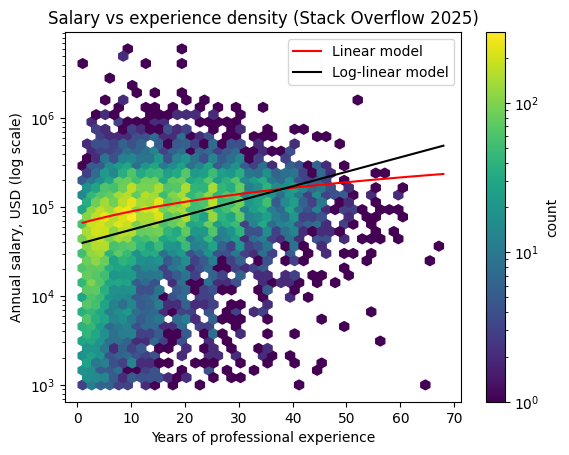

In [47]:
y_log = np.exp(log_regress.intercept + log_regress.slope * x_grid)

plt.hexbin(x=exp_salary['WorkExp'], y=exp_salary['ConvertedCompYearly'], yscale='log', bins='log', gridsize=40)
plt.colorbar(label='count')
plt.plot(x_grid, y_linear, color='red', label='Linear model')
plt.plot(x_grid, y_log, color='black', label='Log-linear model')
plt.xlabel('Years of professional experience')
plt.ylabel('Annual salary, USD (log scale)')
plt.title('Salary vs experience density (Stack Overflow 2025)')
plt.legend()
plt.show()

exp(0.0375) = 1.038 - each year of experience is associated with about 3.8% higher salary, holding nothing else constant.

Because the effect is multiplicative it compounds: ten years correspond to a factor of 1.038¹⁰ ~ 1.45, or 45% more, not 38%. For small coefficients the slope itself is a good approximation of the percentage (0.0375 ~ 3.8%); this shortcut breaks down for larger values.

This figure is a whole-sample estimate mixing all countries and employment types. Chapter B re-estimates it on the defined population and adds country to the model.

In [48]:
np.exp(log_regress.slope)

np.float64(1.03825468403782)

# Chapter B - multiple regression: experience and country

Population: salaried professional developers in the United States, Germany and India (Stack Overflow Developer Survey 2025), n = 6,144. See "Preparation of cleaned data" for the filtering rules.

The question this chapter answers: how much of the salary difference between these three markets is explained by professional experience, and how much by country itself?

Chapter A estimated the effect of experience on the whole survey sample without controlling for country. This chapter shows that the earlier estimate was biased, and by how much.

## Model matrix

The response variable is the natural logarithm of annual salary. Experience enters the model directly; country is encoded as two dummy variables, `is_US` and `is_India`.

Germany receives no column of its own and serves as the reference category: a German respondent is the case where both dummies equal zero. A category of k levels requires k-1 dummies - adding a column for every level would make the design matrix singular, because the dummies would always sum to the constant term.

The dummies are created by explicit comparison rather than by `pd.get_dummies(drop_first=True)`, which drops the first category in alphabetical order. Relying on alphabetical order would silently change the meaning of every coefficient as soon as another country were added.

Germany is chosen as the reference because it is the market this analysis targets: the country coefficients then read as "how much the US and India differ from Germany at the same level of experience".

In [49]:
df_multi = pd.DataFrame({'log_salary': np.log(df_clean['ConvertedCompYearly']), 'WorkExp': df_clean['WorkExp'], 
                         'is_US': df_clean['Country'] == 'United States of America', 'is_India': df_clean['Country'] == 'India'})
df_multi

,log_salary,WorkExp,is_US,is_India
22,11.38,7.00,True,False
29,12.23,19.00,True,False
31,12.43,17.00,True,False
33,12.07,24.00,True,False
35,11.46,10.00,False,False
...,...,...,...,...
48990,12.03,6.00,True,False
49000,11.23,9.00,False,False
49006,12.04,14.00,True,False
49010,9.64,4.00,False,True


## Model 1: experience and country

    log(salary) = a + b₁·WorkExp + b₂·is_US + b₃·is_India

Coefficients are exponentiated to convert them from log units into multipliers:

| Term | Coefficient | exp(coef) | Interpretation |
|------|-------------|-----------|----------------|
| const | 11.0507 | ≈ 63,000 | German respondent with zero experience, USD |
| WorkExp | 0.0180 | 1.018 | +1.8% per year of experience |
| is_US | 0.6244 | 1.867 | US salaries 87% above Germany |
| is_India | −1.2957 | 0.274 | Indian salaries 73% below Germany |

All four coefficients are significant at p < 0.001 and none of the confidence intervals contains zero.

R² = 0.589: experience and country together account for 59% of the variation in log salary. Adjusted R² is 0.588, which means the predictors are earning their place rather than inflating the fit.

Because the model is estimated on logarithms, each coefficient describes a multiplicative effect. Ten years of experience therefore correspond to a factor of 1.018¹⁰ ≈ 1.19, or 19% more, not 18%.

In [50]:
y = df_multi['log_salary']
x = df_multi[['WorkExp', 'is_US', 'is_India']]

x_with_const = sm.add_constant(x)

model = sm.OLS(y, x_with_const)
results = model.fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             log_salary   R-squared:                       0.589
Model:                            OLS   Adj. R-squared:                  0.588
Method:                 Least Squares   F-statistic:                     2929.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:02:45   Log-Likelihood:                -5513.0
No. Observations:                6144   AIC:                         1.103e+04
Df Residuals:                    6140   BIC:                         1.106e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.0507      0.018    604.984      0.000      11.015      11.087
WorkExp        0.0180      0.001     22.209      0.000       0.016       0.020
is_US          0.6244      0.018     34.344      0.000       0.589       0.660
is_India      -1.2957      0.026    -48.987      0.000      -1.348      -1.244
==============================================================================
Omnibus:                      868.527   Durbin-Watson:                   1.973
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             9498.652
Skew:                          -0.291   Prob(JB):                         0.00
Kurtosis:                       9.063   Cond. No.                         70.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Model 2: experience only, same sample

The same regression was run without the country dummies on exactly the same 6,144 observations. Running it on the same sample matters: R² values from models fitted to different data are not comparable.

| | Experience only | Experience and country |
|---|---|---|
| R² | 0.154 | 0.589 |
| WorkExp coefficient | 0.0371 (+3.8%) | 0.0180 (+1.8%) |

Two results follow.

**Country explains far more of the variation than experience does.** Adding two dummy variables raises the explained variance by 43.5 percentage points. Where a developer works predicts their salary roughly four times better than how long they have worked.

**More than half of the apparent effect of experience was not experience at all.** The coefficient drops from 3.8% to 1.8% per year once country is controlled for. This is omitted variable bias: in this sample Indian respondents are both less experienced and far lower paid, so a model without country observes "less experience, less money" and attributes the whole pattern to experience, having no other explanation available to it.

The bias cannot be detected from inside the first model. Its R² is unremarkable but not implausible, its coefficient is highly significant, and its residual diagnostics give no warning. The error becomes visible only once the omitted factor is added. The practical lesson is that the question to ask of a model is not "does it fit well" but "what is missing from it".

The 1.8% figure is the honest one, and it is the one carried into the conclusions.

In [51]:
x_exp = df_multi['WorkExp']
x_exp_with_const = sm.add_constant(x_exp)

exp_model = sm.OLS(y, x_exp_with_const)
exp_model_results = exp_model.fit()
exp_model_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             log_salary   R-squared:                       0.154
Model:                            OLS   Adj. R-squared:                  0.154
Method:                 Least Squares   F-statistic:                     1118.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          2.80e-225
Time:                        14:02:45   Log-Likelihood:                -7728.2
No. Observations:                6144   AIC:                         1.546e+04
Df Residuals:                    6142   BIC:                         1.547e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.0113      0.019    585.841      0.000      10.974      11.048
WorkExp        0.0371      0.001     33.431      0.000       0.035       0.039
==============================================================================
Omnibus:                     1415.834   Durbin-Watson:                   1.819
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4076.421
Skew:                          -1.202   Prob(JB):                         0.00
Kurtosis:                       6.185   Cond. No.                         29.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [52]:
np.exp(11.0113)

np.float64(60554.55662062906)

In [53]:
np.exp(0.0371)

np.float64(1.037796795328879)

## Fitted models by country

Each panel shows the salary–experience density for one country with its own
fitted line. Separate panels are necessary: plotted over a combined density,
the three lines cannot be checked against the data they are meant to
describe.

All three panels share one hexbin grid (`extent`) and one vertical scale
(`sharey=True`). Without this, each panel would compute its own bin
boundaries, cells would differ in size, and colours would encode different
counts in different panels.

The salary axis is logarithmic, so the log-linear models are drawn as
straight lines.

The Indian panel shows a dense cluster below 15 years of experience and
almost no observations beyond it. The fitted line also sits above the densest
part of that cluster at low experience, which suggests that a single common
slope may not describe all three markets equally well. The next section tests
that directly.

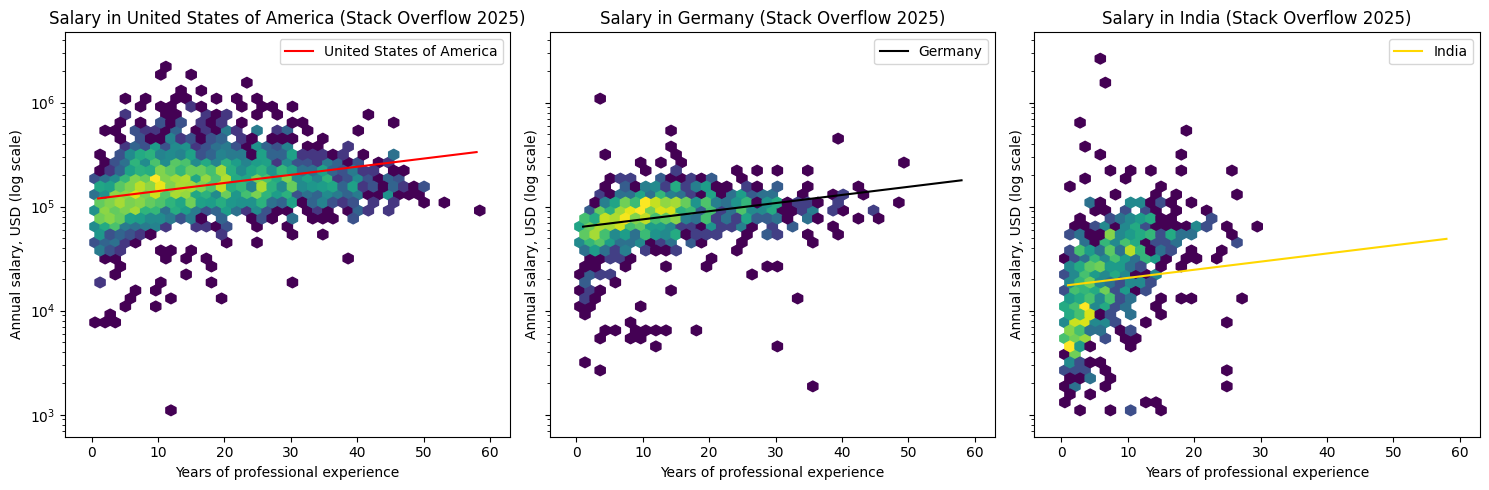

In [54]:
x_grid = np.linspace(df_clean['WorkExp'].min(), df_clean['WorkExp'].max(), 100)
base_log = results.params['const'] + results.params['WorkExp'] * x_grid
y_germany = np.exp(base_log)
y_US = np.exp(base_log + results.params['is_US'])
y_india = np.exp(base_log + results.params['is_India'])

panels = [('United States of America', y_US, 'red'), ('Germany', y_germany, 'black'), ('India', y_india, 'gold')]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
extent_values = (df_clean['WorkExp'].min() - 2, df_clean['WorkExp'].max() + 2, np.log10(df_clean['ConvertedCompYearly'].min()) - 0.1,
                                                                     np.log10(df_clean['ConvertedCompYearly'].max()) + 0.1)

for ax, (country, y_value, color) in zip(axes, panels):
    ax.hexbin(x=df_clean[df_clean['Country'] == country]['WorkExp'], y=df_clean[df_clean['Country'] == country]['ConvertedCompYearly'],
              yscale='log', bins='log', gridsize=40, extent=extent_values)
    ax.plot(x_grid, y_value, color=color, label=country)
    ax.set_xlabel('Years of professional experience')
    ax.set_ylabel('Annual salary, USD (log scale)')
    ax.set_title(f'Salary in {country} (Stack Overflow 2025)')
    ax.legend()

fig.tight_layout()
plt.show()

## Model 3: separate regressions by country

Model 1 assumes that a year of experience is worth the same percentage in all three countries - the three fitted lines differ in height but share one slope. That assumption needs testing rather than accepting.

A separate `log(salary) ~ WorkExp` regression was fitted within each country.

| Country | Slope | 95% CI | R² | n |
|---------|-------|--------|----|---|
| United States | +1.3% | [1.0%; 1.6%] | 0.068 | 3,839 |
| Germany | +1.9% | [1.4%; 2.4%] | 0.086 | 1,521 |
| India | +10.5% | [9.0%; 12.0%] | 0.255 | 784 |

The Indian confidence interval does not overlap the other two. The difference is therefore too large to be attributed to sampling variation, and the common-slope assumption does not hold.

Comparing intervals rather than point estimates is what makes this conclusion defensible. The US and German intervals do overlap, so the difference between those two slopes cannot be asserted.

The R² values point in the same direction. In India experience accounts for 26% of the variation in salary; in the US only 7%. Experience is the dominant factor in the Indian market, while US salaries are driven mainly by characteristics this model does not contain.

A plausible reading is that the gap between junior and senior pay is far wider in a fast-growing market with a shortage of experienced developers, while mature markets have flatter salary structures. The data support the pattern; they do not establish the mechanism.

In [55]:

df_multi_by_country = pd.DataFrame({'log_salary': np.log(df_clean['ConvertedCompYearly']), 'WorkExp': df_clean['WorkExp'], 
                                     'Country': df_clean['Country']})
columns = ['Country', 'const', 'WorkExp', '0.025',	'0.975', 'R-squared','n']
data_list = []
for country in ['United States of America', 'Germany', 'India']:
    df_country_model = df_multi_by_country[df_multi_by_country['Country'] == country]
    x_country = df_country_model['WorkExp']
    y_country = df_country_model['log_salary']
    x_country_with_const = sm.add_constant(x_country)
    country_model = sm.OLS(y_country, x_country_with_const)
    country_results = country_model.fit()
    row = {'Country': country, 'const': np.exp(country_results.params['const']), 'WorkExp': np.exp(country_results.params['WorkExp']), 
           '0.025': np.exp(country_results.conf_int().loc['WorkExp', 0]), '0.975': np.exp(country_results.conf_int().loc['WorkExp', 1]),
           'R-squared': country_results.rsquared, 'n': int(country_results.nobs)}
    data_list.append(row)
df_country_models_results = pd.DataFrame(data_list, columns=columns)
pd.set_option('display.float_format', '{:.4f}'.format)
df_country_models_results

,Country,const,WorkExp,0.025,0.975,R-squared,n
0,United States of America,126013.7902,1.0137,1.0121,1.0153,0.0711,3839
1,Germany,63502.8558,1.0175,1.0146,1.0204,0.0848,1521
2,India,9527.9219,1.1056,1.0923,1.1191,0.2523,784


## Model 4: interaction terms

Interaction terms let the slopes differ across countries instead of only the intercepts. Each term is the product of experience and a country dummy.

    log(salary) = a + b₁·WorkExp + b₂·is_US + b₃·is_India
                    + b₄·(WorkExp × is_US) + b₅·(WorkExp × is_India)

| Term | Coefficient | p-value |
|------|-------------|---------|
| const | 11.0588 | 0.000 |
| WorkExp | 0.0174 | 0.000 |
| is_US | 0.6853 | 0.000 | 
| is_India | -1.8969 | 0.000 |
| WorkExp x is_US | -0.0037 | 0.053 |
| WorkExp x is_India | 0.0831 | 0.000 |

Country slopes are obtained by addition:

| Country | Calculation | Slope |
|---------|-------------|-------|
| Germany (reference) | 0.0174 | +1.76% |
| United States | 0.0174 − 0.0037 | +1.38% |
| India | 0.0174 + 0.0831 | +10.6% |

These reproduce the separate regressions above, which confirms that the model matrix was built correctly.

**The interaction terms turn the slope comparison into a direct test.** `WorkExp x is_India` is significant at p < 0.001: the Indian slope differs from the German one. `WorkExp x is_US` gives p = 0.053 with a confidence interval of [-0.008; 0.00005] that contains zero. The correct statement is that the difference between the US and German slopes does not reach significance at the 5% level - not that no difference exists.

**The country dummies change meaning once interactions are present.** The Indian coefficient moves from -1.2957 to -1.8969. The model has not become less accurate: the coefficient now describes the gap at zero experience rather than a constant gap. exp(-1.8969) = 0.15, so an Indian developer entering the market earns about 15% of a German one. Because the Indian slope is steeper, that gap narrows as experience grows.

Reading such a coefficient as "the effect of country in general" is a common error. In a model with interactions it is only interpretable at zero values of the interacting variable.

R² rises from 0.589 to 0.619. The gain in explanatory power is modest, but the interpretation changes substantially - a model can become more correct without becoming much more accurate.

Setting the Indian and German lines equal gives a convergence point at roughly 23 years of experience. The Indian sample contains very few observations at that level, so this is an extrapolation beyond the data. It should be read as "the observed trend, if it continued, would close the gap around that point", not as a measured fact about senior developers.

In [56]:
pd.set_option('display.float_format', '{:.2f}'.format)
df_multi['WorkExp x is_US'] = df_multi['WorkExp'] * df_multi['is_US']
df_multi['WorkExp x is_India'] = df_multi['WorkExp'] * df_multi['is_India']

x_interaction = df_multi[['WorkExp', 'is_US', 'is_India', 'WorkExp x is_US', 'WorkExp x is_India']]
x_interaction_with_const = sm.add_constant(x_interaction)
interaction_model = sm.OLS(y, x_interaction_with_const)
interaction_model_results = interaction_model.fit()
interaction_model_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             log_salary   R-squared:                       0.619
Model:                            OLS   Adj. R-squared:                  0.619
Method:                 Least Squares   F-statistic:                     1995.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:02:47   Log-Likelihood:                -5277.1
No. Observations:                6144   AIC:                         1.057e+04
Df Residuals:                    6138   BIC:                         1.061e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 11.0588      0.026    426.527      0.000      11.008      11.110
WorkExp                0.0174      0.002     10.102      0.000       0.014       0.021
is_US                  0.6853      0.031     22.156      0.000       0.625       0.746
is_India              -1.8969      0.043    -44.175      0.000      -1.981      -1.813
WorkExp x is_US       -0.0037      0.002     -1.933      0.053      -0.008     5.3e-05
WorkExp x is_India     0.0831      0.004     19.839      0.000       0.075       0.091
==============================================================================
Omnibus:                     1101.493   Durbin-Watson:                   1.955
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            16759.058
Skew:                          -0.401   Prob(JB):                         0.00
Kurtosis:                      11.051   Cond. No.                         154.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Residual diagnostics

A residual is the part of an observation the model fails to explain: the difference between observed and fitted log salary. Structure in the residuals indicates a pattern the model has missed.

**Residuals against fitted values.** The three clusters along the horizontal axis correspond to the three countries, which is the expected consequence of the dummy variables. The spread is comparable across clusters, so there is no pronounced heteroscedasticity. The cloud is not symmetric: negative residuals extend to -5 while positive ones rarely exceed +3.

**Q-Q plot.** The central portion follows the reference line, so the bulk of the residuals is approximately normal. Both tails depart from it, the lower one more sharply. Extreme deviations occur more often than a normal distribution predicts - the graphical form of the excess kurtosis (11.05) reported in the model summary.

Non-normal residuals do not bias the coefficients. Normality matters for the precision of standard errors, and at n = 6,144 the central limit theorem keeps those approximately valid. The heavy tails indicate instead that subgroups exist which experience and country do not describe.

**Residuals by country.** All three medians sit at zero, so the model is not systematically over- or under-predicting for any country. The interquartile range is visibly wider for India: salaries there are predicted less precisely, which is consistent with the much wider internal dispersion of Indian salaries observed in the diagnostics (P75/P25 ratio of 5.0 against 1.6-1.7).

**The most extreme residuals** correspond to records that are implausible for their own labour market - for example a data engineer in the United States with twelve years of experience and a reported annual income of 1,200 USD. These are data-entry errors that survived the lower threshold. The threshold was deliberately set at 1,000 USD so as not to remove genuine low salaries in India, where the 25th percentile is around 8,100 USD; the cost of that decision is that some invalid records remain and make the lower tail heavier.

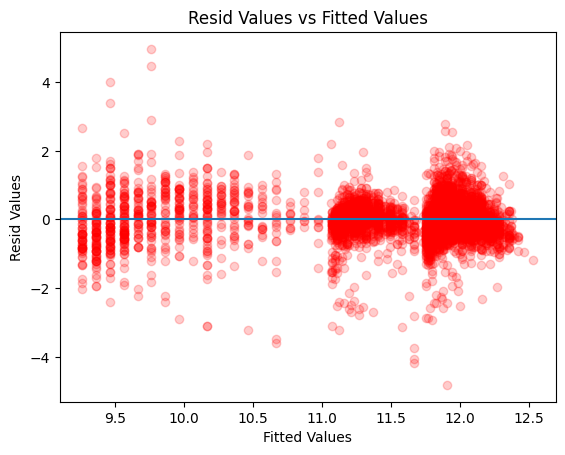

In [57]:
plt.scatter(interaction_model_results.fittedvalues, interaction_model_results.resid, alpha=0.2, color='red')
plt.title('Resid Values vs Fitted Values')
plt.xlabel('Fitted Values')
plt.ylabel('Resid Values')
plt.axhline(0)
plt.show()

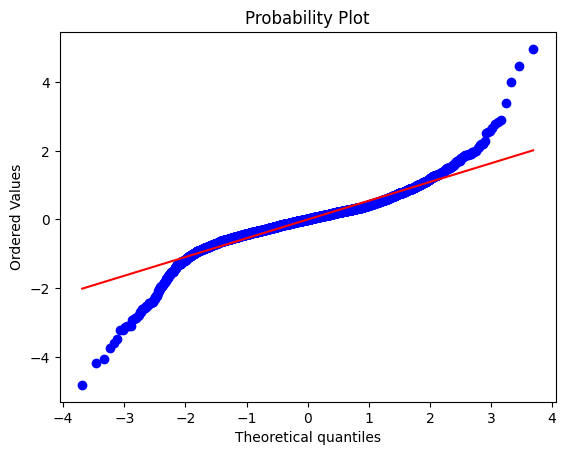

In [58]:
stats.probplot(interaction_model_results.resid, dist='norm', plot=plt)
plt.show()

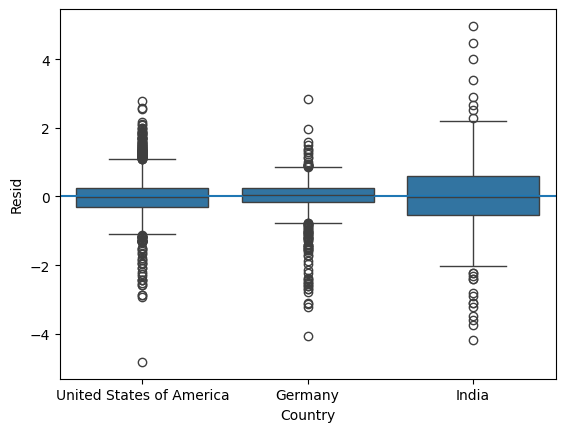

In [59]:
df_clean['Resid'] = interaction_model_results.resid
sns.boxplot(data=df_clean, x='Country', y='Resid')
plt.axhline(0)
plt.show()

In [60]:
df_clean.sort_values(by='Resid').head(10)[['Country', 'ConvertedCompYearly', 'WorkExp', 'DevType', 'OrgSize', 'Resid']]

,Country,ConvertedCompYearly,WorkExp,DevType,OrgSize,Resid
13666,United States of America,1200.00,12.00,Data engineer,100 to 499 employees,-4.82
3593,India,1792.00,25.00,"Developer, mobile","5,000 to 9,999 employees",-4.18
36780,Germany,2000.00,35.00,Academic researcher,20 to 99 employees,-4.07
29282,India,2790.00,25.00,"Developer, back-end","Just me - I am a freelancer, sole proprietor, ...",-3.74
14272,India,1162.00,15.00,"Developer, back-end",100 to 499 employees,-3.61
8273,India,1337.00,15.00,"Developer, full-stack",20 to 99 employees,-3.47
16061,India,1395.00,13.00,"Developer, back-end",20 to 99 employees,-3.23
37221,Germany,2715.00,4.00,"Developer, back-end",Less than 20 employees,-3.22
12750,Germany,4641.00,30.00,Academic researcher,500 to 999 employees,-3.14
35552,India,1162.00,10.00,"Developer, full-stack","Just me - I am a freelancer, sole proprietor, ...",-3.11


## Role composition across countries

If roles were distributed unevenly - junior testers in one country, architects in another - part of the estimated country effect would in fact be a role effect.

The composition is consistent. Full-stack developers account for 34-38% of respondents in all three countries and back-end developers for 16-23%. This supports the interpretation of the country coefficients as market effects rather than differences in occupational mix.

Two smaller differences are worth recording. Front-end developers, a typically lower-paid role, make up 7.8% of the Indian sample against 4.2% in the US. Engineering managers, a higher-paid role, make up 4.2% of the US sample against 2.6% in India. Both differences push in the same direction and slightly inflate the estimated US-India gap.

In [61]:
df_clean.groupby('Country')['DevType'].value_counts(normalize=True)

Country                   DevType                                      
Germany                   Developer, full-stack                           0.35
                          Developer, back-end                             0.17
                          Architect, software or solutions                0.08
                          Developer, desktop or enterprise applications   0.07
                          Developer, front-end                            0.05
                                                                          ... 
United States of America  System administrator                            0.00
                          Financial analyst or engineer                   0.00
                          UX, Research Ops or UI design professional      0.00
                          Project manager                                 0.00
                          Student                                         0.00
Name: proportion, Length: 89, dtype: float64

## Key findings

1. **Country explains salary roughly four times better than experience.** Within this population, experience alone accounts for 15% of the variation in log salary; adding country raises that to 59%.

2. **At equal experience, US salaries are about 87% above German ones and Indian salaries about 73% below.** (Model 1; the gap is not constant across experience levels - see point 4.)

3. **Each year of experience is worth about 1.8% in additional salary once country is controlled for.** The uncontrolled estimate of 3.8% was inflated by omitted variable bias: more than half of the apparent effect of experience was the effect of country.

4. **The return on experience is not the same in every market.** It is about +10.6% per year in India against +1.4% in the US and +1.8% in Germany. The Indian difference is significant at p < 0.001; the difference between the US and Germany is not (p = 0.053).

5. **Experience is the dominant salary factor in India and a marginal one in the US.** Within-country R² is 0.26 for India and 0.07 for the US.

## Limitations

**Non-response.** The salary question was optional. Response rates were 72% in the US, 71% in Germany and 43% in India. Within the filtered Indian population, 689 respondents reported no salary while only 18 were removed by the validity range. Response rates also vary with experience - junior developers answer less often - so the Indian sample is biased towards more experienced respondents and the estimated Indian salary level is likely too high. Non-response cannot be corrected by filtering.

**Excluded groups.** The model covers salaried professional developers only. Freelancers, the self-employed, students and the non-employed are outside the population and the results say nothing about them.

**Residual data-entry errors.** The lower threshold of 1,000 USD was set conservatively to protect genuine low salaries in India. Some implausible records survive it and contribute to the heavy lower tail of the residuals.

**Extrapolation.** The convergence of Indian and German salaries at around 23 years of experience lies outside the range where Indian observations exist.

**Omitted factors.** Role, seniority, company size, industry and region within a country are not in the model. Role composition is similar across the three countries, so it is unlikely to distort the country coefficients, but these factors account for a substantial part of the unexplained variance - particularly in the US, where experience explains only 7% of it.

**Association, not causation.** The model measures statistical association within one survey sample. It does not establish that gaining experience causes a salary increase of a given size, and it does not support predictions about individual developers.

**Single survey, single year.** All results describe the Stack Overflow Developer Survey 2025, whose respondents are self-selected and not a random sample of the developer population in any of the three countries.